# NHS England A&E Performance: University Hospitals of Leicester vs England

**Question:** How does University Hospitals of Leicester (UHL) perform against the four-hour A&E standard compared with England – and is the comparison fair?

**Data:** NHS England monthly A&E Attendances and Emergency Admissions (provider level), October 2024 – September 2026 (24 months). Public data, Open Government Licence.

**Tools:** Python (pandas, Matplotlib, SciPy, requests) · SQLite

**Author:** Bekir Onal

In [61]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
print("pandas version:", pd.__version__)


pandas version: 3.0.6


In [62]:
df = pd.read_csv("data/ae_2026_09.csv")
print(df.shape)
df.head()

(192, 22)


,Period,Org Code,Parent Org,Org name,A&E attendances Type 1,A&E attendances Type 2,A&E attendances Other A&E Department,A&E attendances Booked Appointments Type 1,A&E attendances Booked Appointments Type 2,A&E attendances Booked Appointments Other Department,...,Attendances over 4hrs Other Department,Attendances over 4hrs Booked Appointments Type 1,Attendances over 4hrs Booked Appointments Type 2,Attendances over 4hrs Booked Appointments Other Department,Patients who have waited 4-12 hs from DTA to admission,Patients who have waited 12+ hrs from DTA to admission,Emergency admissions via A&E - Type 1,Emergency admissions via A&E - Type 2,Emergency admissions via A&E - Other A&E department,Other emergency admissions
0,MSitAE-SEPTEMBER-2026,AJN,NHS ENGLAND NORTH EAST AND YORKSHIRE,WORKINGTON HEALTH LIMITED,0,0,492,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,MSitAE-SEPTEMBER-2026,NTV0B,NHS ENGLAND SOUTH EAST,ASHFORD WALK-IN-CENTRE,0,0,2584,0,0,0,...,273,0,0,0,0,0,0,0,0,0
2,MSitAE-SEPTEMBER-2026,NTV0W,NHS ENGLAND SOUTH EAST,WOKING WALK IN CENTRE,0,0,2773,0,0,0,...,84,0,0,0,0,0,0,0,0,0
3,MSitAE-SEPTEMBER-2026,RYY,NHS ENGLAND SOUTH EAST,KENT COMMUNITY HEALTH NHS FOUNDATION TRUST,0,0,6655,0,0,0,...,95,0,0,0,0,0,0,0,0,0
4,MSitAE-SEPTEMBER-2026,AAH,NHS ENGLAND SOUTH WEST,TETBURY HOSPITAL TRUST LTD,0,0,702,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [63]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 192 entries, 0 to 191
Data columns (total 22 columns):
 #   Column                                                      Non-Null Count  Dtype
---  ------                                                      --------------  -----
 0   Period                                                      192 non-null    str  
 1   Org Code                                                    192 non-null    str  
 2   Parent Org                                                  192 non-null    str  
 3   Org name                                                    192 non-null    str  
 4   A&E attendances Type 1                                      192 non-null    int64
 5   A&E attendances Type 2                                      192 non-null    int64
 6   A&E attendances Other A&E Department                        192 non-null    int64
 7   A&E attendances Booked Appointments Type 1                  192 non-null    int64
 8   A&E attendances Booked Appointm

In [64]:
df.isnull().sum().sum()

np.int64(0)

In [65]:
uhl = df[df["Org Code"] == "RWE"]
uhl



,Period,Org Code,Parent Org,Org name,A&E attendances Type 1,A&E attendances Type 2,A&E attendances Other A&E Department,A&E attendances Booked Appointments Type 1,A&E attendances Booked Appointments Type 2,A&E attendances Booked Appointments Other Department,...,Attendances over 4hrs Other Department,Attendances over 4hrs Booked Appointments Type 1,Attendances over 4hrs Booked Appointments Type 2,Attendances over 4hrs Booked Appointments Other Department,Patients who have waited 4-12 hs from DTA to admission,Patients who have waited 12+ hrs from DTA to admission,Emergency admissions via A&E - Type 1,Emergency admissions via A&E - Type 2,Emergency admissions via A&E - Other A&E department,Other emergency admissions
156,MSitAE-SEPTEMBER-2026,RWE,NHS ENGLAND MIDLANDS,UNIVERSITY HOSPITALS OF LEICESTER NHS TRUST,24152,2198,0,0,0,0,...,0,0,0,0,1140,499,6766,5,0,3841


In [66]:
uhl.T

,156
Period,MSitAE-SEPTEMBER-2026
Org Code,RWE
Parent Org,NHS ENGLAND MIDLANDS
Org name,UNIVERSITY HOSPITALS OF LEICESTER NHS TRUST
A&E attendances Type 1,24152
A&E attendances Type 2,2198
A&E attendances Other A&E Department,0
A&E attendances Booked Appointments Type 1,0
A&E attendances Booked Appointments Type 2,0
A&E attendances Booked Appointments Other Department,0


In [ ]:
# Step 9a - UHL four-hour performance (September 2026).
attendance_cols = [c for c in df.columns if c.startswith("A&E attendances")]
over_4hrs_cols = [c for c in df.columns if c.startswith("Attendances over 4hrs")]
total_attendances = uhl[attendance_cols].sum(axis=1).iloc[0]
over_4hrs = uhl[over_4hrs_cols].sum(axis=1).iloc[0]
performance = (total_attendances- over_4hrs) / total_attendances * 100
print(f"Total attendances: {total_attendances:,}")
print(f"Waited over 4 hours: {over_4hrs:,}")
print(f"Four-hour performance: {performance:.1f}%")


Total attendances: 26,350
Waited over 4 hours: 9,991
Four-hour performance: 62.1%


In [ ]:
# Step 9b - England four-hour performance (September 2026)
# The file has a "TOTAL" row for England, so it must not be added to the providers again
england = df[df["Org Code"] == "TOTAL"]
providers = df[df["Org Code"] != "TOTAL"]
eng_attendances = england[attendance_cols].sum(axis=1).iloc[0]
eng_over_4hrs = england[over_4hrs_cols].sum(axis=1).iloc[0]
# Check: the TOTAL row should equal the sum of all providers
check_attendances = providers[attendance_cols].sum().sum()
print(f"TOTAL row matches providers: {eng_attendances == check_attendances}")
eng_performance = (eng_attendances - eng_over_4hrs) / eng_attendances * 100
target = 82
print(f"England four-hour performance: {eng_performance:.1f}%")
print(f"UHL four-hour performance: {performance:.1f}%")
print(f"UHL vs England: {performance - eng_performance:+.1f} percentage points")
print(f"UHL vs 82% target: {performance - target:+.1f} percentage points")



TOTAL row matches providers: True
England four-hour performance: 74.4%
UHL four-hour performance: 62.1%
UHL vs England: -12.3 percentage points
UHL vs 82% target: -19.9 percentage points


In [69]:
# Step 9c - Fair comparison: Type 1 (major A&E departments) only
type1_att_cols = ["A&E attendances Type 1", "A&E attendances Booked Appointments Type 1"]
type1_over_cols = ["Attendances over 4hrs Type 1", "Attendances over 4hrs Booked Appointments Type 1"]
def four_hour_performances(rows, att_cols, over_cols):
    attendances = rows[att_cols].sum().sum()
    over = rows[over_cols].sum().sum()
    return (attendances - over) / attendances * 100
uhl_type1 = four_hour_performances(uhl, type1_att_cols, type1_over_cols)
eng_type1 = four_hour_performances(england, type1_att_cols, type1_over_cols)
print(f"UHL Type 1 performance: {uhl_type1:.1f}%")
print(f"England Type 1 performance: {eng_type1:.1f}%")
print(f"UHL vs England (Type 1 only): {uhl_type1 - eng_type1:.1f} percentage points")



UHL Type 1 performance: 59.4%
England Type 1 performance: 60.6%
UHL vs England (Type 1 only): -1.2 percentage points


In [ ]:
# Step 10b - Download 24 months of A&E data (Oct 2024 - Sep 2026)
import requests
from pathlib import Path
data_dir = Path("data/monthly")
data_dir.mkdir(parents = True, exist_ok=True)
lines = Path("data/urls.txt").read_text().splitlines()
for line in lines:
    month, url = line.split()
    target = data_dir / f"ae_{month.replace('-','_')}.csv"
    if target.exists():
        print(f"Already downloaded: {target.name}")
        continue
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    target.write_bytes(response.content)
    print(f"Downloaded: {target.name} ({len(response.content):,} bytes)")
print(f"\nFiles in data/monthly: {len(list(data_dir.glob('*.csv')))}")



Already downloaded: ae_2024_10.csv
Already downloaded: ae_2024_11.csv
Already downloaded: ae_2024_12.csv
Already downloaded: ae_2025_01.csv
Already downloaded: ae_2025_02.csv
Already downloaded: ae_2025_03.csv
Already downloaded: ae_2025_04.csv
Already downloaded: ae_2025_05.csv
Already downloaded: ae_2025_06.csv
Already downloaded: ae_2025_07.csv
Already downloaded: ae_2025_08.csv
Already downloaded: ae_2025_09.csv
Already downloaded: ae_2025_10.csv
Already downloaded: ae_2025_11.csv
Already downloaded: ae_2025_12.csv
Already downloaded: ae_2026_01.csv
Already downloaded: ae_2026_02.csv
Already downloaded: ae_2026_03.csv
Already downloaded: ae_2026_04.csv
Already downloaded: ae_2026_05.csv
Already downloaded: ae_2026_06.csv
Already downloaded: ae_2026_07.csv
Already downloaded: ae_2026_08.csv
Already downloaded: ae_2026_09.csv

Files in data/monthly: 24


In [71]:
# Step 10c — Combine the 24 monthly files into one table
import pandas as pd

frames = []
for file in sorted(data_dir.glob("ae_*.csv")):
    month_df = pd.read_csv(file)
    month_df["month"] = pd.to_datetime(file.stem[3:], format="%Y_%m")
    frames.append(month_df)

all_months = pd.concat(frames, ignore_index=True)

print("TOTAL rows before cleaning:", (all_months["Org Code"] == "TOTAL").sum())

# Clean text columns: remove extra spaces and make Org Code upper case
text_cols = ["Period", "Org Code", "Parent Org", "Org name"]
for col in text_cols:
    all_months[col] = all_months[col].str.strip()
all_months["Org Code"] = all_months["Org Code"].str.upper()

print("TOTAL rows after cleaning:", (all_months["Org Code"] == "TOTAL").sum())
print("Rows, columns:", all_months.shape)
print("Months:", all_months["month"].nunique())

TOTAL rows before cleaning: 21
TOTAL rows after cleaning: 24
Rows, columns: (4745, 23)
Months: 24


In [72]:
# Step 11a - Monthly Type 1 four-hour performance: UHL vs England
rows = []
for month, month_rows in all_months.groupby("month"):
    uhl_rows = month_rows[month_rows["Org Code"] == "RWE"]
    england_rows = month_rows[month_rows["Org Code"] == "TOTAL"]
    rows.append({
        "month": month,
        "UHL": four_hour_performances(uhl_rows, type1_att_cols, type1_over_cols),
        "England": four_hour_performances(england_rows, type1_att_cols, type1_over_cols),
    })

monthly = pd.DataFrame(rows).set_index("month")
monthly["Gap"] = monthly["UHL"] - monthly["England"]

print(monthly.round(1))
print(f"\nMonths where UHL beat England: {(monthly['Gap'] > 0).sum()} of {len(monthly)}")

             UHL  England  Gap
month                         
2024-10-01  56.7     58.1 -1.4
2024-11-01  54.9     57.0 -2.1
2024-12-01  56.5     55.3  1.2
2025-01-01  56.7     57.7 -1.0
2025-02-01  57.8     58.4 -0.6
2025-03-01  56.1     60.9 -4.8
2025-04-01  56.7     60.2 -3.5
2025-05-01  58.8     61.2 -2.4
2025-06-01  58.2     61.7 -3.6
2025-07-01  61.9     63.1 -1.2
2025-08-01  60.6     62.0 -1.5
2025-09-01  59.4     61.1 -1.7
2025-10-01  60.1     60.1 -0.1
2025-11-01  59.4     60.3 -1.0
2025-12-01  63.4     59.6  3.8
2026-01-01  59.2     57.3  1.9
2026-02-01  60.1     59.4  0.8
2026-03-01  63.8     64.1 -0.3
2026-04-01  63.1     63.8 -0.8
2026-05-01  60.5     61.9 -1.4
2026-06-01  61.5     61.2  0.3
2026-07-01  60.8     61.7 -0.9
2026-08-01  61.3     61.1  0.2
2026-09-01  59.4     60.6 -1.2

Months where UHL beat England: 6 of 24


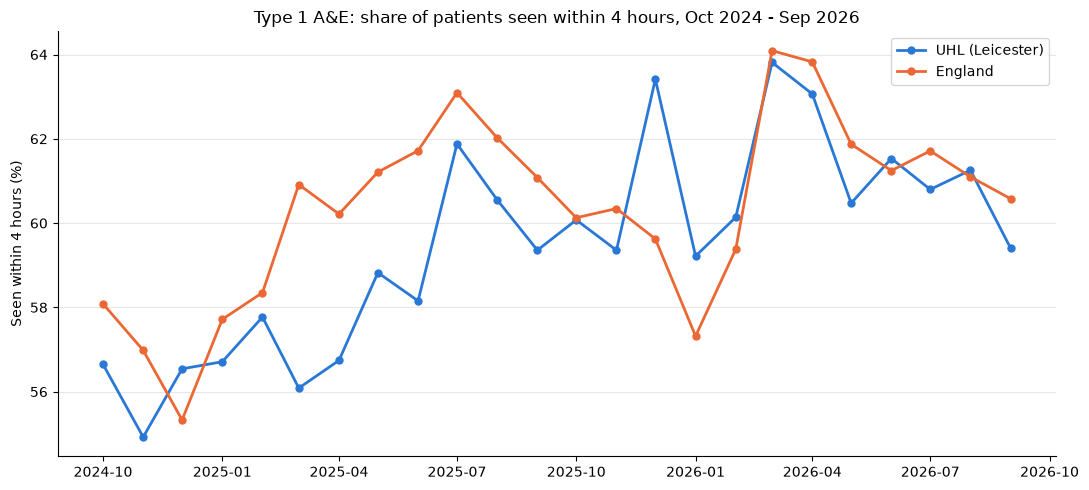

In [73]:
# Step 11b - Line chart: UHL vs England, Type 1, 24 months
Path("images").mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(monthly.index, monthly["UHL"], color="#2a78d6", linewidth=2,
        marker="o", markersize=5, label="UHL (Leicester)")
ax.plot(monthly.index, monthly["England"], color="#eb6834", linewidth=2,
        marker="o", markersize=5, label="England")

ax.set_title("Type 1 A&E: share of patients seen within 4 hours, Oct 2024 - Sep 2026")
ax.set_ylabel("Seen within 4 hours (%)")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend()

plt.tight_layout()
plt.savefig("images/uhl_vs_england_type1.png", dpi=150)
plt.show()

In [74]:
# Step 11c - Winter effect: December-February vs the rest of the year
is_winter = monthly.index.month.isin([12, 1, 2])
monthly["Season"] = "Rest of year"
monthly.loc[is_winter, "Season"] = "Winter (Dec-Feb)"

season_avg = monthly.groupby("Season")[["UHL", "England", "Gap"]].mean()
print(season_avg.round(1))
print("\nWinter months in the data:", is_winter.sum())

                   UHL  England  Gap
Season                              
Rest of year      59.6     61.1 -1.5
Winter (Dec-Feb)  59.0     58.0  1.0

Winter months in the data: 6


In [75]:
# Step 11d - Is the winter difference real or just chance? (Mann-Whitney U test)
for col in ["England", "UHL", "Gap"]:
    winter = monthly.loc[is_winter, col]
    rest = monthly.loc[~is_winter, col]
    result = stats.mannwhitneyu(winter, rest, alternative="two-sided")
    print(f"{col:8} winter mean {winter.mean():5.1f} | rest mean {rest.mean():5.1f} | p = {result.pvalue:.4f}")

England  winter mean  58.0 | rest mean  61.1 | p = 0.0010
UHL      winter mean  59.0 | rest mean  59.6 | p = 0.4537
Gap      winter mean   1.0 | rest mean  -1.5 | p = 0.0025


In [76]:
# Step 11e - Patient numbers: did UHL see fewer Type 1 patients in winter?
uhl_all = all_months[all_months["Org Code"] == "RWE"].set_index("month")
england_all = all_months[all_months["Org Code"] == "TOTAL"].set_index("month")

monthly["UHL attendances"] = uhl_all[type1_att_cols].sum(axis=1)
monthly["England attendances"] = england_all[type1_att_cols].sum(axis=1)

volume_avg = monthly.groupby("Season")[["UHL attendances", "England attendances"]].mean()
print(volume_avg.round(0))

change = (volume_avg.loc["Winter (Dec-Feb)"] / volume_avg.loc["Rest of year"] - 1) * 100
print("\nWinter vs rest of year (% change):")
print(change.round(1))

                  UHL attendances  England attendances
Season                                                
Rest of year              22585.0            1452872.0
Winter (Dec-Feb)          21404.0            1373607.0

Winter vs rest of year (% change):
UHL attendances       -5.2
England attendances   -5.5
dtype: float64


In [77]:
# Step 11f - Are winter patients sicker? Admission rate and 12-hour waits
admission_cols = ["Emergency admissions via A&E - Type 1",
                  "Emergency admissions via A&E - Type 2",
                  "Emergency admissions via A&E - Other A&E department"]
wait_12h_col = "Patients who have waited 12+ hrs from DTA to admission"

for name, rows in [("UHL", uhl_all), ("England", england_all)]:
    attendances = rows[type1_att_cols].sum(axis=1)
    monthly[f"{name} admission rate"] = rows["Emergency admissions via A&E - Type 1"] / attendances * 100
    monthly[f"{name} 12h wait share"] = rows[wait_12h_col] / rows[admission_cols].sum(axis=1) * 100

cols = ["UHL admission rate", "England admission rate", "UHL 12h wait share", "England 12h wait share"]
print(monthly.groupby("Season")[cols].mean().round(1).T)

Season                  Rest of year  Winter (Dec-Feb)
UHL admission rate              29.5              30.7
England admission rate          27.4              28.2
UHL 12h wait share              11.8              13.6
England 12h wait share          11.3              14.4


In [78]:
# Step 12a - Load the 24 months into a SQLite database
import re
import sqlite3

sql_df = all_months.copy()
sql_df.columns = [re.sub(r"[^a-z0-9]+", "_", col.lower()).strip("_") for col in sql_df.columns]
sql_df["month"] = sql_df["month"].dt.strftime("%Y-%m")

conn = sqlite3.connect("data/nhs_ae.db")
sql_df.to_sql("ae_monthly", conn, if_exists="replace", index=False)

print(list(sql_df.columns))
pd.read_sql("SELECT COUNT(*) AS row_count, COUNT(DISTINCT month) AS months FROM ae_monthly", conn)

['period', 'org_code', 'parent_org', 'org_name', 'a_e_attendances_type_1', 'a_e_attendances_type_2', 'a_e_attendances_other_a_e_department', 'a_e_attendances_booked_appointments_type_1', 'a_e_attendances_booked_appointments_type_2', 'a_e_attendances_booked_appointments_other_department', 'attendances_over_4hrs_type_1', 'attendances_over_4hrs_type_2', 'attendances_over_4hrs_other_department', 'attendances_over_4hrs_booked_appointments_type_1', 'attendances_over_4hrs_booked_appointments_type_2', 'attendances_over_4hrs_booked_appointments_other_department', 'patients_who_have_waited_4_12_hs_from_dta_to_admission', 'patients_who_have_waited_12_hrs_from_dta_to_admission', 'emergency_admissions_via_a_e_type_1', 'emergency_admissions_via_a_e_type_2', 'emergency_admissions_via_a_e_other_a_e_department', 'other_emergency_admissions', 'month']


,row_count,months
0,4745,24


In [79]:
# Step 12b - Monthly Type 1 four-hour performance in SQL (UHL vs England)
query = """
WITH type1 AS (
    SELECT month, org_code,
           a_e_attendances_type_1 + a_e_attendances_booked_appointments_type_1 AS attendances,
           attendances_over_4hrs_type_1 + attendances_over_4hrs_booked_appointments_type_1 AS over_4hrs
    FROM ae_monthly
    WHERE org_code IN ('RWE', 'TOTAL')
)
SELECT month,
       100.0 * SUM(CASE WHEN org_code = 'RWE' THEN attendances - over_4hrs END)
             / SUM(CASE WHEN org_code = 'RWE' THEN attendances END) AS uhl,
       100.0 * SUM(CASE WHEN org_code = 'TOTAL' THEN attendances - over_4hrs END)
             / SUM(CASE WHEN org_code = 'TOTAL' THEN attendances END) AS england
FROM type1
GROUP BY month
ORDER BY month
"""
monthly_sql = pd.read_sql(query, conn)
monthly_sql["gap"] = monthly_sql["uhl"] - monthly_sql["england"]
print(monthly_sql.round(1))

      month   uhl  england  gap
0   2024-10  56.7     58.1 -1.4
1   2024-11  54.9     57.0 -2.1
2   2024-12  56.5     55.3  1.2
3   2025-01  56.7     57.7 -1.0
4   2025-02  57.8     58.4 -0.6
5   2025-03  56.1     60.9 -4.8
6   2025-04  56.7     60.2 -3.5
7   2025-05  58.8     61.2 -2.4
8   2025-06  58.2     61.7 -3.6
9   2025-07  61.9     63.1 -1.2
10  2025-08  60.6     62.0 -1.5
11  2025-09  59.4     61.1 -1.7
12  2025-10  60.1     60.1 -0.1
13  2025-11  59.4     60.3 -1.0
14  2025-12  63.4     59.6  3.8
15  2026-01  59.2     57.3  1.9
16  2026-02  60.1     59.4  0.8
17  2026-03  63.8     64.1 -0.3
18  2026-04  63.1     63.8 -0.8
19  2026-05  60.5     61.9 -1.4
20  2026-06  61.5     61.2  0.3
21  2026-07  60.8     61.7 -0.9
22  2026-08  61.3     61.1  0.2
23  2026-09  59.4     60.6 -1.2


In [80]:
# Step 12c - Save the monthly query as a SQL view, then compare winter with the rest of the year
conn.execute("DROP VIEW IF EXISTS monthly_type1")
conn.execute("CREATE VIEW monthly_type1 AS " + query)

season_query = """
SELECT CASE WHEN substr(month, 6, 2) IN ('12', '01', '02') THEN 'Winter (Dec-Feb)'
            ELSE 'Rest of year' END AS season,
       COUNT(*) AS months,
       ROUND(AVG(uhl), 1) AS uhl,
       ROUND(AVG(england), 1) AS england,
       ROUND(AVG(uhl - england), 1) AS gap
FROM monthly_type1
GROUP BY season
ORDER BY season
"""
pd.read_sql(season_query, conn)

,season,months,uhl,england,gap
0,Rest of year,18,59.6,61.1,-1.5
1,Winter (Dec-Feb),6,59.0,58.0,1.0


In [81]:
# Step 12d - Check that SQL and Python give exactly the same monthly results
sql_side = monthly_sql.set_index("month")[["uhl", "england"]]

python_side = monthly[["UHL", "England"]].copy()
python_side.index = python_side.index.strftime("%Y-%m")
python_side.columns = ["uhl", "england"]

diff = (sql_side - python_side).abs().max()
print("Largest difference between SQL and Python:")
print(diff)
print("Match:", (diff < 1e-9).all())

Largest difference between SQL and Python:
uhl        7.105427e-15
england    1.421085e-14
dtype: float64
Match: True


In [82]:
# Step 12e - Save the SQL queries to a file for the repository
sql_text = (
    "-- NHS England A&E analysis: SQL queries (SQLite)\n"
    "-- Table ae_monthly: 24 monthly provider files (Oct 2024 - Sep 2026), snake_case columns\n\n"
    "-- 1. Monthly Type 1 four-hour performance: UHL (RWE) vs England (TOTAL row)\n"
    "DROP VIEW IF EXISTS monthly_type1;\n"
    "CREATE VIEW monthly_type1 AS" + query + ";\n\n"
    "-- 2. Winter (December-February) vs the rest of the year\n"
    + season_query.strip() + ";\n"
)
Path("queries.sql").write_text(sql_text)
print(Path("queries.sql").read_text())

-- NHS England A&E analysis: SQL queries (SQLite)
-- Table ae_monthly: 24 monthly provider files (Oct 2024 - Sep 2026), snake_case columns

-- 1. Monthly Type 1 four-hour performance: UHL (RWE) vs England (TOTAL row)
DROP VIEW IF EXISTS monthly_type1;
CREATE VIEW monthly_type1 AS
WITH type1 AS (
    SELECT month, org_code,
           a_e_attendances_type_1 + a_e_attendances_booked_appointments_type_1 AS attendances,
           attendances_over_4hrs_type_1 + attendances_over_4hrs_booked_appointments_type_1 AS over_4hrs
    FROM ae_monthly
    WHERE org_code IN ('RWE', 'TOTAL')
)
SELECT month,
       100.0 * SUM(CASE WHEN org_code = 'RWE' THEN attendances - over_4hrs END)
             / SUM(CASE WHEN org_code = 'RWE' THEN attendances END) AS uhl,
       100.0 * SUM(CASE WHEN org_code = 'TOTAL' THEN attendances - over_4hrs END)
             / SUM(CASE WHEN org_code = 'TOTAL' THEN attendances END) AS england
FROM type1
GROUP BY month
ORDER BY month
;

-- 2. Winter (December-February) vs th